# MSDS 565 — Unit 1, Notebook 5: Interpretability & Fairness
**Team DataStars**

Explain the selected-feature Random Forest from Notebook 4 with SHAP and evaluate subgroup errors using Fairlearn. This notebook follows **P1_Prompt.pdf, page 7** and reuses the held-out split; it does not refit a model or create a new split.

**Run provenance:** The user authorized rebuilding the missing artifacts from `CarSales_Large.csv`. This notebook analyzes that **new rebuild**, not the original Notebook 4 saved run. Preprocessing follows the supplied Notebook 2 code; feature ranking and VIF follow Notebook 4. The final Random Forest reuses Notebook 4's recorded winning hyperparameters (200 trees, `max_features=0.5`, `min_samples_leaf=1`, no depth limit). No new grid search or cross-validation is claimed. The reconstruction is kept outside this notebook in `rebuild/rebuild_artifacts.py` to preserve the assignment's separation of modeling and interpretation.

## 1. Setup and artifact provenance
Notebook 4's executed tables report Random Forest as the strongest selected-feature model: test MAE **\$1,701.09**, MAPE **7.16%**, and R² **0.9473**, using 94 features. Those figures describe the original run, not the rebuilt model evaluated below. The original full-feature forest was slightly more accurate, but the assignment explicitly calls for the selected model.

**Inputs included in this project:** `data/selected_test.csv`, `models/P1_N4_rf_selected.pkl`, and `data/model_metrics_selected.csv`, all from the same rebuilt run. The selected training export and reconstruction logs are retained for reproducibility.

The supplied Notebook 2 records 336 numeric features and 59,243 test rows; Notebook 4 records 293 original numeric features and 59,317 test rows before selection. Those are different artifact histories. The supplied `CarSales_Small.csv` also has a different schema (49 columns, including `make`/`model`) from the earlier notebook data (66 raw columns, including `make_name`/`model_name`). Rebuilding from that CSV would not reproduce this model's test split. The supplied larger CSV matches the 302,590-row, 66-column input used by Notebook 2, so the rebuild uses it and yields 236,972 training rows and 59,243 test rows.

The bundled `requirements.txt` records the actual rebuild/execution packages. Use that environment to load this rebuilt model. The assignment separately requests a conda environment export from the team's submission environment; this pip package record does not replace it.

**Feature-set distinction:** This reconstruction also retains 94 predictors, but they are not the original Notebook 4's 94 predictors. For example, the rebuild's VIF procedure removes `horsepower` after importance ranking. Therefore SHAP should not be expected to repeat Notebook 4's importance ordering.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from fairlearn.metrics import MetricFrame
from IPython.display import display, Markdown

SEED = 42
SHAP_SAMPLE_SIZE = 200
SHAP_WORKERS = 8  # independent CPU workers; reduce on smaller machines
MIN_GROUP_N = 30  # descriptive stability flag, not a significance threshold
AUDIT_COLUMNS = ["make_name", "body_type", "fuel_type"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
MAROON, GOLD, SLATE = "#7B1E3B", "#C9A227", "#3F4A56"
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_columns", 12)


/Users/ironcloth/Documents/Codex/2026-09-22/hel/work/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.1 Locate the saved inputs
The defaults follow the prompt's `repo/notebooks/` and `repo/models/` structure and also handle Notebook 4's nested-folder convention. If the data live in a separate class folder, edit `DATA_DIR`. Edit `MODEL_PATH` if necessary. Only load your team's trusted model file.


In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "models").is_dir()), cwd)
DATA_DIR = PROJECT_ROOT / "data"  # EDIT to your local class data folder
MODEL_PATH = PROJECT_ROOT / "models" / "P1_N4_rf_selected.pkl"
TEST_PATH = DATA_DIR / "selected_test.csv"
METRICS_PATH = DATA_DIR / "model_metrics_selected.csv"  # optional
OUTPUT_DIR = PROJECT_ROOT / "reports" / "notebook5"

missing = [str(p) for p in [TEST_PATH, MODEL_PATH] if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing matching Notebook 4 exports:\n" + "\n".join(missing)
                            + "\nEdit DATA_DIR / MODEL_PATH, then run all cells again.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", TEST_PATH.resolve())
print("Model:", MODEL_PATH.resolve())


Dataset: /Users/ironcloth/Documents/Codex/2026-09-22/hel/outputs/Notebook5_Project/data/selected_test.csv
Model: /Users/ironcloth/Documents/Codex/2026-09-22/hel/outputs/Notebook5_Project/models/P1_N4_rf_selected.pkl


### 1.2 Load and validate the model feature order
Notebook 4 fitted its model using importance-ranked feature order but exported selected CSV columns in their original order. Passing the CSV's numeric columns straight to the model could therefore misalign inputs. We use `feature_names_in_` from the fitted forest to recover the exact training order. Metadata and the target never enter the feature matrix. The already-scaled features are **not scaled again**.


In [3]:
test_df = pd.read_csv(TEST_PATH, low_memory=False).reset_index(drop=True)
rf_selected = joblib.load(MODEL_PATH)
if not isinstance(rf_selected, RandomForestRegressor):
    raise TypeError("Expected the saved selected-feature RandomForestRegressor.")
if not hasattr(rf_selected, "feature_names_in_"):
    raise ValueError("Model has no saved feature names. Recover its exact training column order; do not guess.")
feature_names = list(rf_selected.feature_names_in_)
metadata_cols = test_df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
assert len(feature_names) == len(set(feature_names)), "Duplicate model feature names."
assert "price" in test_df and "price" not in feature_names
assert not set(feature_names).intersection(metadata_cols), "Metadata entered the model inputs."
missing_features = set(feature_names) - set(test_df.columns)
assert not missing_features, f"Missing model features: {sorted(missing_features)}"
assert all(c in metadata_cols for c in AUDIT_COLUMNS), "Missing text metadata for the three audits."
X_test = test_df.loc[:, feature_names].copy()
y_test = pd.to_numeric(test_df["price"], errors="raise")
assert X_test.select_dtypes(exclude=np.number).empty, "Non-numeric model input."
assert np.isfinite(X_test.to_numpy(dtype=float)).all(), "Missing/infinite model inputs."
assert np.isfinite(y_test).all() and (y_test > 0).all(), "MAPE needs finite, positive prices here."
assert len(y_test) >= 4, "Need at least four observations for distinct local examples."
assert X_test.shape[1] == rf_selected.n_features_in_
print(f"Test rows: {len(test_df):,}; model features: {X_test.shape[1]}; metadata columns: {len(metadata_cols)}")
rebuild_path = PROJECT_ROOT / "rebuild" / "rebuild_manifest.json"
if rebuild_path.exists():
    rebuild_info = json.loads(rebuild_path.read_text())
    assert len(test_df) == rebuild_info["test_shape"][0]
    assert feature_names == rebuild_info["selected_features"]
    print("Verified against the new rebuild manifest. Original Notebook 4 results remain a separate run.")

    print("Rebuild started from", rebuild_info["features_before_selection"], "numeric predictors.")
    print("VIF removals:", ", ".join(item["feature"] for item in rebuild_info["vif_removed"]))


Test rows: 59,243; model features: 94; metadata columns: 19
Verified against the new rebuild manifest. Original Notebook 4 results remain a separate run.
Rebuild started from 336 numeric predictors.
VIF removals: fuel_type_Unknown, length, highway_fuel_economy, power_hp, is_new, horsepower


## 2. Evaluate the full held-out test set
MAE is the mean absolute error in dollars; MAPE is the mean absolute percentage error; R² compares errors with a constant-mean prediction. We retain MAPE as a fraction internally, matching Notebooks 3–4, and multiply by 100 for presentation. Signed error is **predicted minus actual**, so positive values indicate overpricing. All audit metrics use the entire test set, not the SHAP sample.


In [4]:
predictions = np.asarray(rf_selected.predict(X_test)).reshape(-1)
assert np.isfinite(predictions).all() and len(predictions) == len(y_test)
evaluation = test_df[AUDIT_COLUMNS].copy()
evaluation.insert(0, "test_row", np.arange(len(test_df)))
evaluation["actual_price"] = y_test.to_numpy()
evaluation["predicted_price"] = predictions
evaluation["signed_error"] = predictions - y_test.to_numpy()
evaluation["absolute_error"] = evaluation["signed_error"].abs()
evaluation["absolute_percentage_error"] = evaluation["absolute_error"] / y_test.to_numpy()
overall = pd.Series({"MAE": mean_absolute_error(y_test, predictions),
                     "MAPE": mean_absolute_percentage_error(y_test, predictions),
                     "R2": r2_score(y_test, predictions)}, name="Selected Random Forest")
display(pd.DataFrame({"MAE ($)": [overall["MAE"]], "MAPE (%)": [overall["MAPE"] * 100], "R2": [overall["R2"]]}).round(4))
if METRICS_PATH.exists():
    prior_metrics = pd.read_csv(METRICS_PATH, index_col=0)
    prior = prior_metrics.loc["Random Forest", ["Test MAE", "Test MAPE", "Test R2"]].to_numpy(dtype=float)
    check = pd.DataFrame({"Input metrics export": prior, "Recomputed": overall.to_numpy()}, index=overall.index)
    display(check.round(6))
    if not np.allclose(prior, overall.to_numpy(), rtol=1e-4, atol=1e-4):
        raise ValueError("Metrics differ from Input metrics export: resolve model/data mismatch before interpretation.")
else:
    print("Optional Notebook 4 metrics file not found; exact artifact consistency is not independently verified.")


,MAE ($),MAPE (%),R2
0,1666.5302,7.1795,0.9577


,Input metrics export,Recomputed
MAE,1666.530195,1666.530195
MAPE,0.071795,0.071795
R2,0.957656,0.957656


## 3. Global SHAP explanations
We take a reproducible random sample of 200 test listings. To handle this large forest reliably, we compute exact `tree_path_dependent` SHAP for each of its 200 fitted trees, then average the contributions and baselines. A Random Forest prediction is the mean of its tree predictions; SHAP's linearity property therefore gives the forest explanation by the same averaging operation. This changes computation, not the fitted model. Eight independent workers speed up the calculation.

The baseline uses the saved trees' training-path counts. No targets enter the explainer, and no model is fitted. This SHAP convention describes the model's learned associations; it is not a causal effect or a perfect estimate of a conditional feature distribution. Correlated features can share or shift attribution, even after VIF filtering. Contributions are in price dollars, while input values remain standardized.

We compute the random sample and four deliberately selected local examples together, then use only the random 200 listings for the beeswarm. This avoids repeating expensive calculations without mixing the selected error extremes into the global summary. The final additivity check verifies that baseline plus contributions equals the saved forest's predictions. Tree-wise calculation takes several minutes; progress is printed every 20 trees and saved to `shap_progress.json`.


Explained 20/200 trees; elapsed 73 seconds.


Explained 40/200 trees; elapsed 127 seconds.


Explained 60/200 trees; elapsed 206 seconds.


Explained 80/200 trees; elapsed 260 seconds.


Explained 100/200 trees; elapsed 341 seconds.


Explained 120/200 trees; elapsed 404 seconds.


Explained 140/200 trees; elapsed 488 seconds.


Explained 160/200 trees; elapsed 555 seconds.


Explained 180/200 trees; elapsed 633 seconds.


Explained 200/200 trees; elapsed 696 seconds.


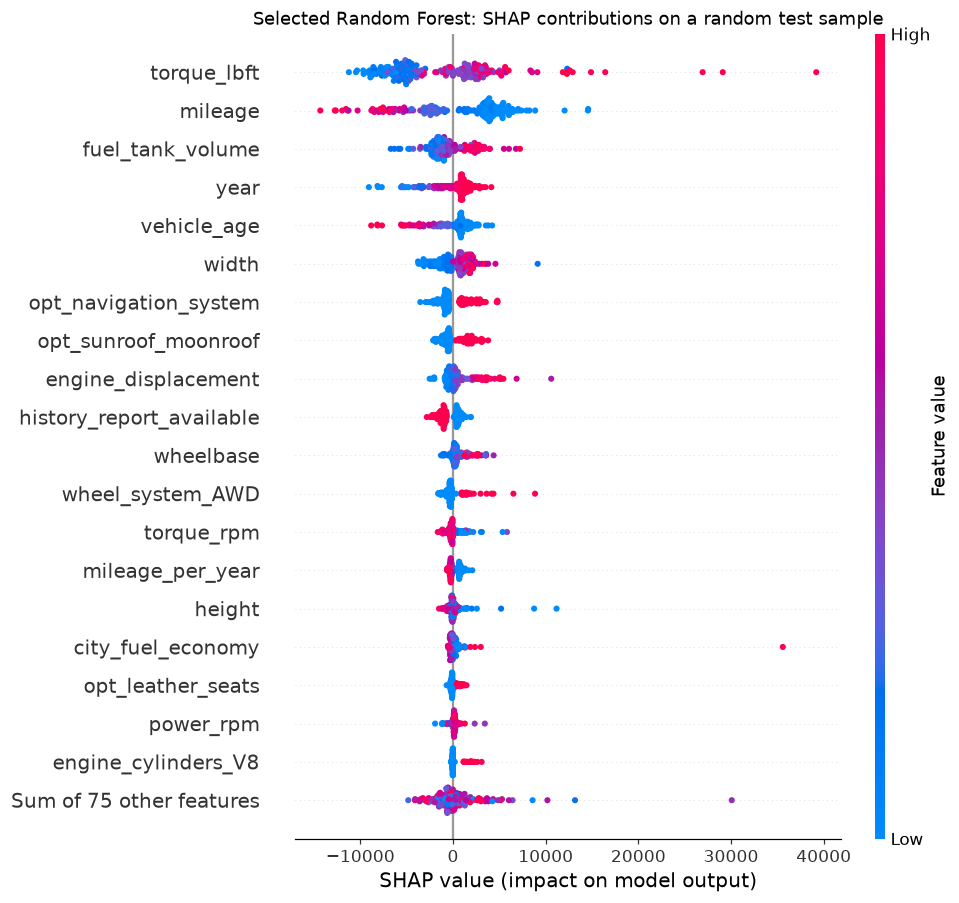

,feature,mean_absolute_SHAP
0,torque_lbft,5284.10
1,mileage,4741.38
2,fuel_tank_volume,1785.27
3,year,1647.86
4,vehicle_age,1603.53
5,width,1414.22
6,opt_navigation_system,1339.31
7,opt_sunroof_moonroof,1136.77
8,engine_displacement,964.08
9,history_report_available,934.97


In [5]:
import time
from joblib import Parallel, delayed, parallel_config

X_shap = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=SEED)
ordered_for_shap = evaluation.sort_values(["absolute_error", "test_row"])
local_rows_for_shap = (ordered_for_shap.head(2)["test_row"].tolist()
                      + ordered_for_shap.tail(2).sort_values("absolute_error", ascending=False)["test_row"].tolist())
explain_rows = list(dict.fromkeys(X_shap.index.tolist() + local_rows_for_shap))
X_explain = X_test.loc[explain_rows]

def explain_one_tree(tree, samples):
    # Each worker loads only one tree into SHAP, avoiding a large forest-wide array.
    import shap
    import numpy as np
    tree_explainer = shap.TreeExplainer(tree, feature_perturbation="tree_path_dependent", model_output="raw")
    result = tree_explainer(samples, check_additivity=True)
    return np.asarray(result.values), np.asarray(result.base_values).reshape(-1)

sum_values = np.zeros(X_explain.shape, dtype=float)
sum_baselines = np.zeros(len(X_explain), dtype=float)
start_shap = time.perf_counter()
with parallel_config(backend="loky", n_jobs=SHAP_WORKERS, inner_max_num_threads=1):
    tree_results = Parallel(return_as="generator", batch_size=1, pre_dispatch=SHAP_WORKERS)(
        delayed(explain_one_tree)(tree, X_explain.to_numpy()) for tree in rf_selected.estimators_
    )
    for completed, (tree_values, tree_baselines) in enumerate(tree_results, start=1):
        sum_values += tree_values
        sum_baselines += tree_baselines
        if completed % 20 == 0 or completed == len(rf_selected.estimators_):
            progress = {"trees_completed": completed, "total_trees": len(rf_selected.estimators_),
                        "elapsed_seconds": round(time.perf_counter() - start_shap, 1)}
            (OUTPUT_DIR / "shap_progress.json").write_text(json.dumps(progress))
            print(f"Explained {completed}/{len(rf_selected.estimators_)} trees; "
                  f"elapsed {progress['elapsed_seconds']:.0f} seconds.")

forest_values = sum_values / len(rf_selected.estimators_)
forest_baselines = sum_baselines / len(rf_selected.estimators_)
np.testing.assert_allclose(forest_baselines + forest_values.sum(axis=1), rf_selected.predict(X_explain),
                           rtol=1e-5, atol=0.05)
forest_explanation = shap.Explanation(values=forest_values, base_values=forest_baselines,
                                     data=X_explain.to_numpy(), feature_names=feature_names)
row_position = {row: position for position, row in enumerate(explain_rows)}
shap_values = forest_explanation[[row_position[row] for row in X_shap.index]]
assert shap_values.values.shape == X_shap.shape
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title("Selected Random Forest: SHAP contributions on a random test sample")
plt.savefig(OUTPUT_DIR / "shap_beeswarm.png", bbox_inches="tight", dpi=160)
plt.show()
shap_importance = pd.DataFrame({"feature": feature_names,
                                "mean_absolute_SHAP": np.abs(shap_values.values).mean(axis=0)})
shap_importance = shap_importance.sort_values("mean_absolute_SHAP", ascending=False).reset_index(drop=True)
display(shap_importance.head(10).round(2))


### 3.1 Interpreting what the forest relies on
In the beeswarm, features are ranked by mean absolute contribution. Points to the right raise predicted price relative to the baseline; points to the left lower it. Color denotes a high or low **scaled feature value**, not the size of the error. Notebook 4's impurity-based ranking emphasized horsepower and mileage, so those are hypotheses to compare against this held-out SHAP ranking, not assumed SHAP findings.

Vehicle power, usage, size, age, and equipment are plausible signals for listing price. Brand/category dummies can proxy market segment. Missingness flags or geographic features deserve scrutiny because their association may reflect collection practices or market composition. SHAP importance alone cannot establish why a relationship exists.


In this rebuild, `horsepower` was removed during VIF filtering, so it cannot appear directly in SHAP. The retained `torque_lbft` feature captures a related powertrain signal. `year` and `vehicle_age` contain overlapping age information; interpret their attributions together rather than as independent physical effects.

In [6]:
top_names = shap_importance.head(5)["feature"].tolist()
display(Markdown("**Observed leading SHAP features:** " + ", ".join(f"`{f}`" for f in top_names) + "."))
for feature in top_names[:3]:
    j = feature_names.index(feature)
    x = X_shap[feature].to_numpy()
    lo, hi = np.quantile(x, [0.25, 0.75])
    if lo < hi:
        low_effect = shap_values.values[x <= lo, j].mean()
        high_effect = shap_values.values[x >= hi, j].mean()
        display(Markdown(f"- **{feature}:** mean SHAP contribution is \\${low_effect:,.0f} for the lower-value "
                         f"quarter (including ties) and \\${high_effect:,.0f} for the higher-value quarter. "
                         "This is a descriptive comparison within the sample, not a controlled effect."))
    else:
        display(Markdown(f"- **{feature}:** quartiles coincide because of repeated values; "
                         "use the beeswarm to inspect category-specific contributions."))


**Observed leading SHAP features:** `torque_lbft`, `mileage`, `fuel_tank_volume`, `year`, `vehicle_age`.

- **torque_lbft:** mean SHAP contribution is \$-7,052 for the lower-value quarter (including ties) and \$6,191 for the higher-value quarter. This is a descriptive comparison within the sample, not a controlled effect.

- **mileage:** mean SHAP contribution is \$5,003 for the lower-value quarter (including ties) and \$-6,731 for the higher-value quarter. This is a descriptive comparison within the sample, not a controlled effect.

- **fuel_tank_volume:** mean SHAP contribution is \$-1,808 for the lower-value quarter (including ties) and \$2,197 for the higher-value quarter. This is a descriptive comparison within the sample, not a controlled effect.

## 4. Local SHAP: two close predictions and two large errors
Select the two smallest and two largest **absolute dollar errors** across the full test set. Show actual and predicted prices and percentage errors so an expensive vehicle's large dollar error is not confused with an unusually large proportional error. These are deliberately chosen extremes, not a representative accuracy sample. `test_row` is the zero-based CSV row position, not a vehicle identifier.


In [7]:
ordered = evaluation.sort_values(["absolute_error", "test_row"])
close_rows = ordered.head(2)["test_row"].tolist()
large_rows = ordered.tail(2).sort_values("absolute_error", ascending=False)["test_row"].tolist()
case_rows = close_rows + large_rows
assert len(set(case_rows)) == 4
case_table = evaluation.iloc[case_rows].copy()
case_table.insert(0, "case", ["Close 1", "Close 2", "Large error 1", "Large error 2"])
display(case_table.round(3))
local_shap = forest_explanation[[row_position[row] for row in case_rows]]
np.testing.assert_allclose(np.asarray(local_shap.base_values).reshape(-1) + local_shap.values.sum(axis=1),
                           predictions[case_rows], rtol=1e-5, atol=0.05)


,case,test_row,make_name,body_type,fuel_type,actual_price,predicted_price,signed_error,absolute_error,absolute_percentage_error
1184,Close 1,1184,Honda,Sedan,Gasoline,27935.0,27935.000,0.000,0.000,0.000
2424,Close 2,2424,Honda,Hatchback,Gasoline,17945.0,17945.000,0.000,0.000,0.000
55004,Large error 1,55004,Jeep,SUV / Crossover,Gasoline,199500.0,33054.975,-166445.025,166445.025,0.834
33885,Large error 2,33885,Dodge,Sedan,Unknown,169900.0,19814.545,-150085.455,150085.455,0.883


### 4.1 Force plots and individual interpretations
Red contributions push the estimate upward; blue contributions push it downward. Each plot explains the **predicted** price, not the residual itself. A large error can arise from missing vehicle condition information, sparse training support, unusual prices, or limitations of the forest; the force plot alone cannot distinguish these causes. Static plots retain visibility in a saved notebook without requiring JavaScript.


**Observed local examples:** The two close examples are Honda listings whose predictions exactly match their recorded prices. The two largest dollar errors are a Jeep listed at \$199,500 (prediction about \$33,055) and a Dodge listed at \$169,900 (prediction about \$19,815). Their absolute percentage errors are about 83.4% and 88.3%. The available features move predictions toward ordinary price levels rather than these extreme recorded prices. Verify the original listing prices, trim/condition details, and training support before deciding whether these are data errors or genuine unusual vehicles; SHAP alone cannot settle that question.

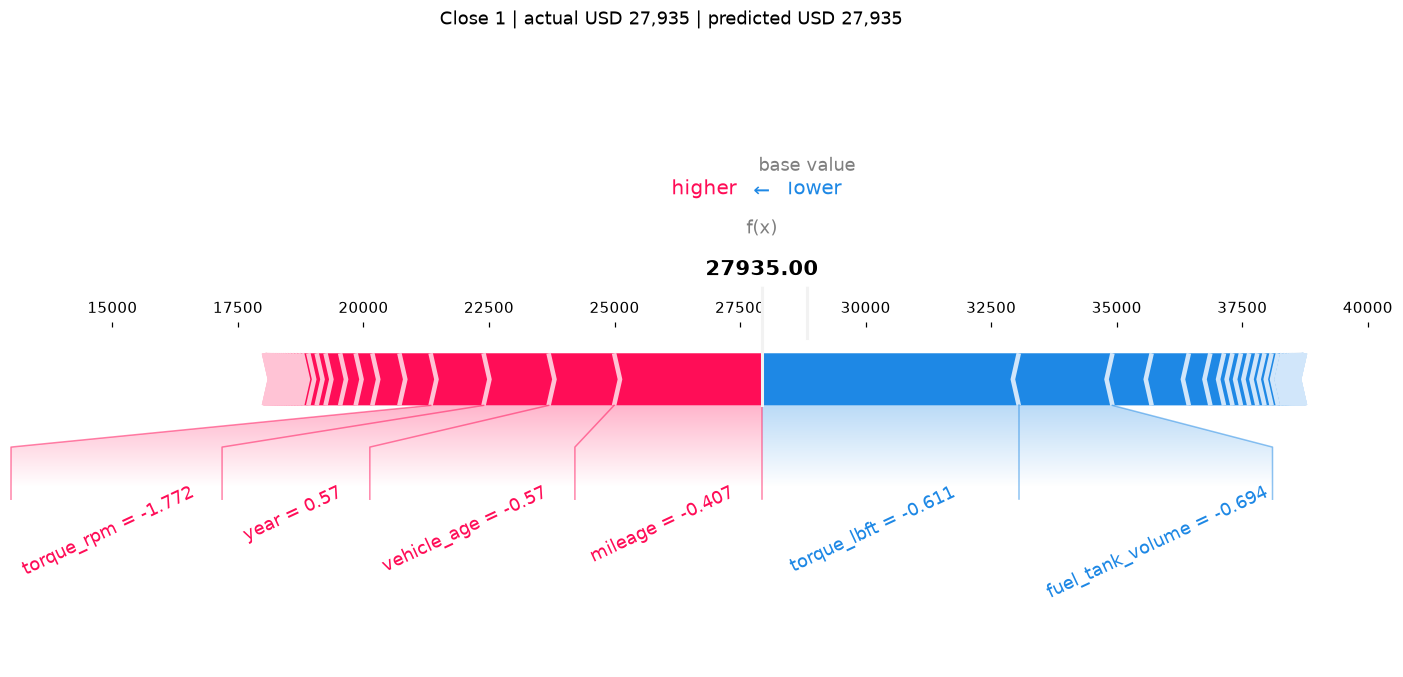

**Close 1, test row 1184:** baseline \$28,832; prediction \$27,935; actual \$27,935. The model matched by \$0 (0.00% absolute error). Largest contributions: torque_lbft: -5,114 dollars; mileage: +2,944 dollars; fuel_tank_volume: -1,866 dollars. All feature contributions sum to prediction minus baseline.

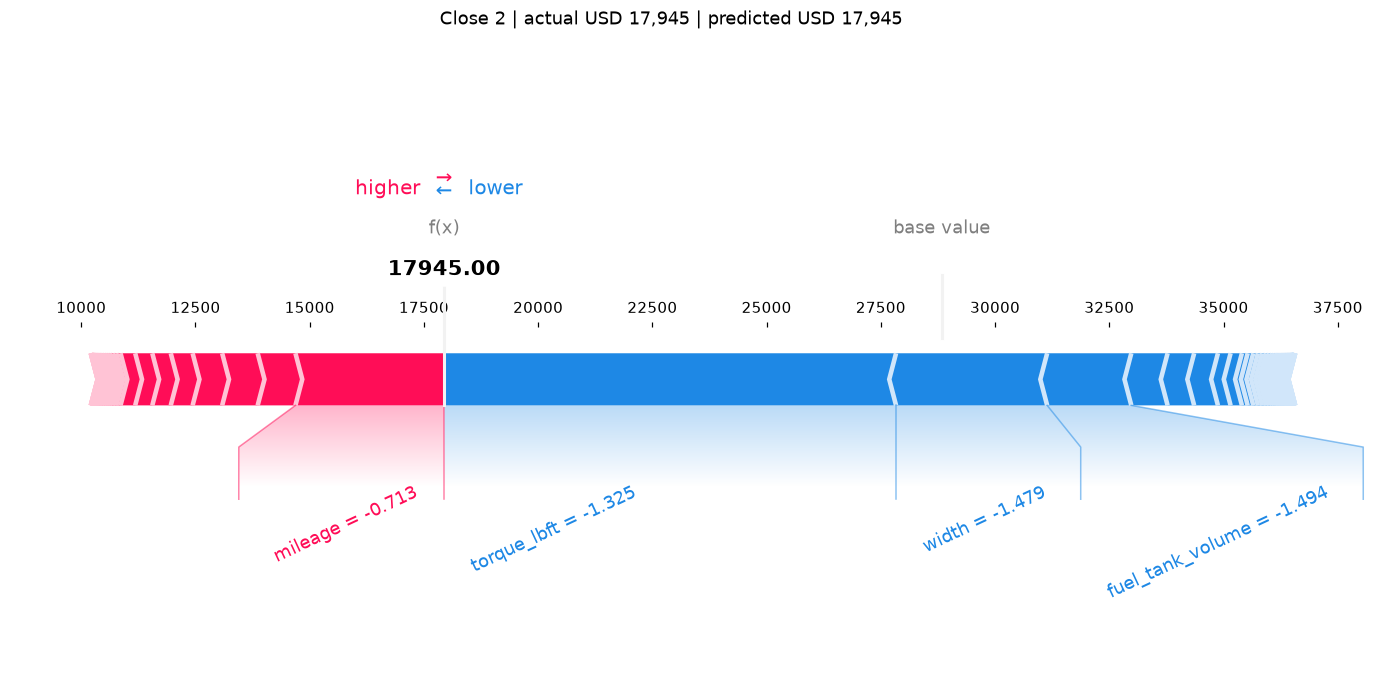

**Close 2, test row 2424:** baseline \$28,832; prediction \$17,945; actual \$17,945. The model matched by \$0 (0.00% absolute error). Largest contributions: torque_lbft: -9,888 dollars; width: -3,307 dollars; mileage: +3,257 dollars. All feature contributions sum to prediction minus baseline.

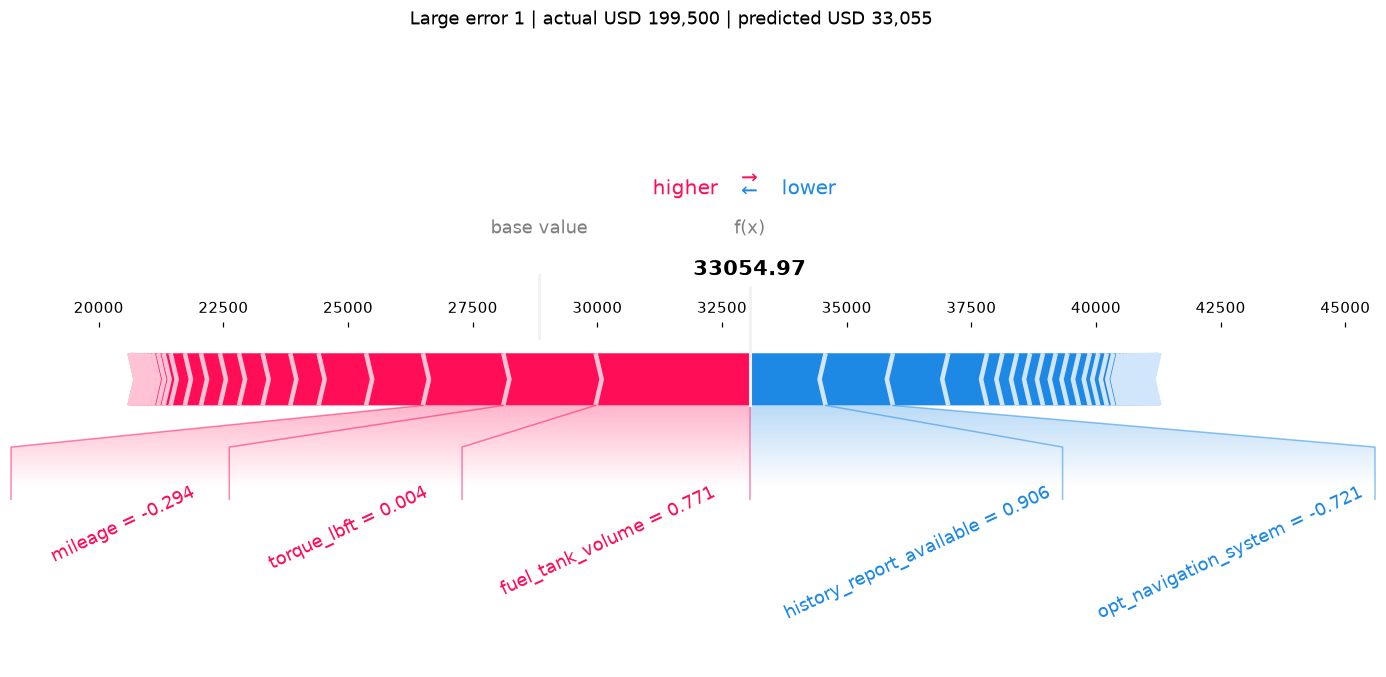

**Large error 1, test row 55004:** baseline \$28,832; prediction \$33,055; actual \$199,500. The model underpredicted by \$166,445 (83.43% absolute error). Largest contributions: fuel_tank_volume: +3,090 dollars; torque_lbft: +1,851 dollars; mileage: +1,612 dollars. All feature contributions sum to prediction minus baseline.

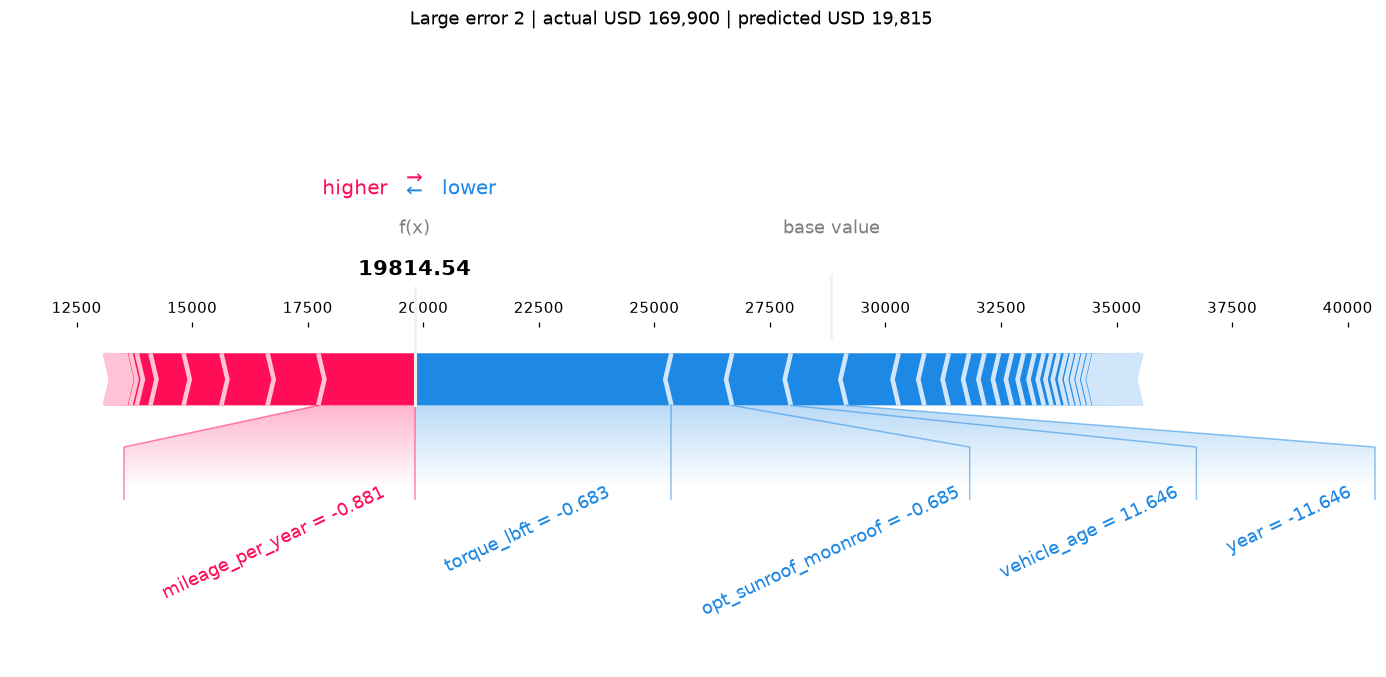

**Large error 2, test row 33885:** baseline \$28,832; prediction \$19,815; actual \$169,900. The model underpredicted by \$150,085 (88.34% absolute error). Largest contributions: torque_lbft: -5,554 dollars; mileage_per_year: +2,085 dollars; opt_sunroof_moonroof: -1,315 dollars. All feature contributions sum to prediction minus baseline.

In [8]:
local_contributions = []
for i, (_, row) in enumerate(case_table.iterrows()):
    case = row["case"]
    values = local_shap.values[i]
    baseline = float(np.asarray(local_shap.base_values).reshape(-1)[i])
    shap.plots.force(baseline, values, X_test.iloc[case_rows[i]].round(3), matplotlib=True,
                     show=False, figsize=(16, 4), text_rotation=25, contribution_threshold=0.08)
    plt.gcf().suptitle(f"{case} | actual USD {row.actual_price:,.0f} | predicted USD {row.predicted_price:,.0f}", y=1.6)
    # Offset the baseline label vertically if it is close to the prediction label.
    if abs(row.predicted_price - baseline) < 2000:
        for annotation in plt.gca().texts:
            if annotation.get_text() == "base value":
                x_pos, y_pos = annotation.get_position()
                annotation.set_position((x_pos, y_pos + 0.12))
    plt.savefig(OUTPUT_DIR / f"force_{i+1}.png", bbox_inches="tight", dpi=160)
    plt.show()
    contributions = pd.Series(values, index=feature_names)
    strongest = contributions.abs().nlargest(3).index
    explanation = "; ".join(f"{f}: {contributions[f]:+,.0f} dollars" for f in strongest)
    direction = "overpredicted" if row.signed_error > 0 else "underpredicted" if row.signed_error < 0 else "matched"
    display(Markdown(f"**{case}, test row {int(row.test_row)}:** baseline \\${baseline:,.0f}; "
                     f"prediction \\${row.predicted_price:,.0f}; actual \\${row.actual_price:,.0f}. "
                     f"The model {direction} by \\${row.absolute_error:,.0f} "
                     f"({row.absolute_percentage_error:.2%} absolute error). "
                     f"Largest contributions: {explanation}. "
                     "All feature contributions sum to prediction minus baseline."))
    local_contributions.append(pd.DataFrame({"case": case, "test_row": int(row.test_row),
                                            "feature": feature_names, "SHAP": values}))


## 5. Fairness audit using retained subgroup metadata
We audit **make_name**, **body_type**, and **fuel_type** independently. Make tests market-segment variation; body type tests differences among vehicle designs; fuel type tests powertrain segments that may have uneven representation. These are product subgroups, not human protected attributes. Disparity is an error pattern worth investigating, not proof of unlawful discrimination or a complete demographic fairness assessment.

Fairlearn's `MetricFrame` calculates MAE, MAPE, and R² for **every observed category** in the complete held-out set. We also report counts, average actual price, and mean signed error. Missing metadata are labeled explicitly rather than discarded. Groups with fewer than 30 observations are flagged as small; they remain in the exports. R² is undefined for fewer than two observations or constant targets, and is shown as missing in those cases. Negative R² is possible and is retained.


In [9]:
def safe_r2(y_true, y_pred):
    actual = np.asarray(y_true, dtype=float)
    return np.nan if len(actual) < 2 or np.ptp(actual) == 0 else r2_score(actual, y_pred)

def sample_count(y_true, y_pred):
    return len(y_true)

def mean_actual(y_true, y_pred):
    return float(np.mean(y_true))

def mean_signed_error(y_true, y_pred):
    return float(np.mean(np.asarray(y_pred) - np.asarray(y_true)))

metrics = {"MAE": mean_absolute_error, "MAPE": mean_absolute_percentage_error, "R2": safe_r2,
           "n": sample_count, "mean_price": mean_actual, "mean_signed_error": mean_signed_error}
audit_frames, audit_tables = {}, {}
for column in AUDIT_COLUMNS:
    groups = test_df[column].astype("string").fillna("[Missing metadata]")
    frame = MetricFrame(metrics=metrics, y_true=y_test.to_numpy(), y_pred=predictions,
                        sensitive_features=groups.rename(column))
    table = frame.by_group.copy()
    table["n"] = table["n"].astype(int)
    table["small_group"] = table["n"] < MIN_GROUP_N
    table["MAPE_percent"] = 100 * table["MAPE"]
    table["MAE_over_mean_price"] = table["MAE"] / table["mean_price"]
    assert table["n"].sum() == len(test_df)
    np.testing.assert_allclose(np.average(table["MAE"], weights=table["n"]), overall["MAE"])
    audit_frames[column], audit_tables[column] = frame, table
    display(Markdown(f"### {column}: {len(table)} categories; top 15 by sample count"))
    display(table.sort_values("n", ascending=False).head(15).round(4))
    print("All categories are retained in the exported CSV, including small groups.")


### make_name: 60 categories; top 15 by sample count

,MAE,MAPE,R2,n,mean_price,mean_signed_error,small_group,MAPE_percent,MAE_over_mean_price
make_name,,,,,,,,,
Ford,1841.1780,0.0776,0.9597,8151,31138.1156,126.9273,False,7.7646,0.0591
Chevrolet,1568.0224,0.0735,0.9539,6538,27600.7828,111.2448,False,7.3508,0.0568
Toyota,1249.7135,0.0665,0.9631,4983,23733.3136,-97.7329,False,6.6491,0.0527
Nissan,1065.4056,0.0662,0.9669,4728,20828.6153,150.1763,False,6.6247,0.0512
Honda,824.4832,0.0465,0.9814,4217,24179.6644,-68.2141,False,4.6459,0.0341
Jeep,1841.8208,0.0689,0.9047,2975,30756.1267,90.3636,False,6.8921,0.0599
Hyundai,917.7201,0.0596,0.9703,2839,20416.0743,108.4386,False,5.9556,0.0450
Kia,987.3159,0.0626,0.9563,2332,19405.7320,218.6076,False,6.2612,0.0509
Volkswagen,1177.9367,0.0686,0.9703,1964,22038.6130,143.3037,False,6.8598,0.0534


All categories are retained in the exported CSV, including small groups.


### body_type: 10 categories; top 15 by sample count

,MAE,MAPE,R2,n,mean_price,mean_signed_error,small_group,MAPE_percent,MAE_over_mean_price
body_type,,,,,,,,,
SUV / Crossover,1530.3039,0.0591,0.9682,27160,30760.1890,11.0603,False,5.9128,0.0497
Sedan,1338.5630,0.0784,0.9555,16300,21670.3328,41.2749,False,7.8369,0.0618
Pickup Truck,2237.8976,0.0737,0.9487,8050,39561.7178,24.8703,False,7.3720,0.0566
Hatchback,1081.0669,0.0882,0.9572,1917,16550.0814,38.6804,False,8.8162,0.0653
Coupe,3958.2164,0.1248,0.8915,1741,35314.8693,-483.4058,False,12.4765,0.1121
Minivan,1415.6483,0.0839,0.9682,1537,24709.5257,148.8524,False,8.3937,0.0573
Wagon,1447.4487,0.0925,0.9273,850,19436.8724,-150.3037,False,9.2470,0.0745
Van,1970.3321,0.0901,0.9001,794,26769.5264,109.0881,False,9.0069,0.0736
Convertible,3511.4996,0.1304,0.9483,623,35979.3941,-506.7994,False,13.0377,0.0976


All categories are retained in the exported CSV, including small groups.


### fuel_type: 8 categories; top 15 by sample count

,MAE,MAPE,R2,n,mean_price,mean_signed_error,small_group,MAPE_percent,MAE_over_mean_price
fuel_type,,,,,,,,,
Gasoline,1529.3877,0.0681,0.9673,51834,28339.2005,5.5694,False,6.8136,0.0540
Flex Fuel Vehicle,1864.4786,0.0964,0.9561,2808,25618.9747,240.0439,False,9.6369,0.0728
Unknown,4984.7564,0.1487,0.7561,1605,38458.2199,-316.2819,False,14.8720,0.1296
Hybrid,1149.7571,0.0573,0.9737,1454,25636.2070,-152.0656,False,5.7296,0.0448
Diesel,2582.4179,0.0901,0.9567,778,40500.3458,-161.6015,False,9.0130,0.0638
Biodiesel,3454.8130,0.0700,0.8972,390,57187.0692,-458.9989,False,7.0036,0.0604
Electric,3182.8414,0.0817,0.9749,370,42057.9703,377.6240,False,8.1657,0.0757
Compressed Natural Gas,3520.1400,0.3348,0.4237,4,9517.7500,3520.1400,True,33.4795,0.3699


All categories are retained in the exported CSV, including small groups.


### 5.1 Visualize error disparities
Three panels per audit compare MAE, MAPE, and R². We display up to 15 largest groups by count for readability; chart titles state how many categories are shown. Full results for all categories are exported. The dashed line is the overall test metric. Group count appears in each label, and gold marks groups below the descriptive count threshold. Differences are not statistical significance tests.


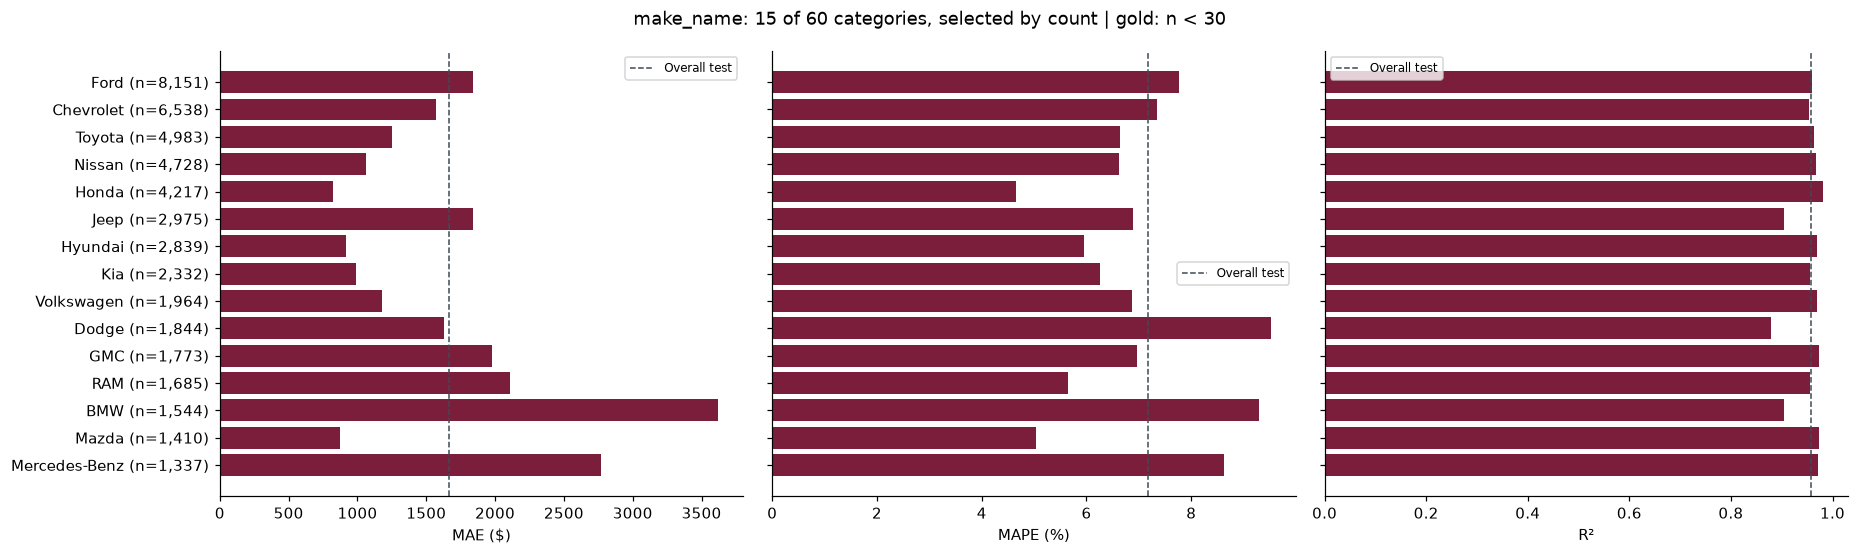

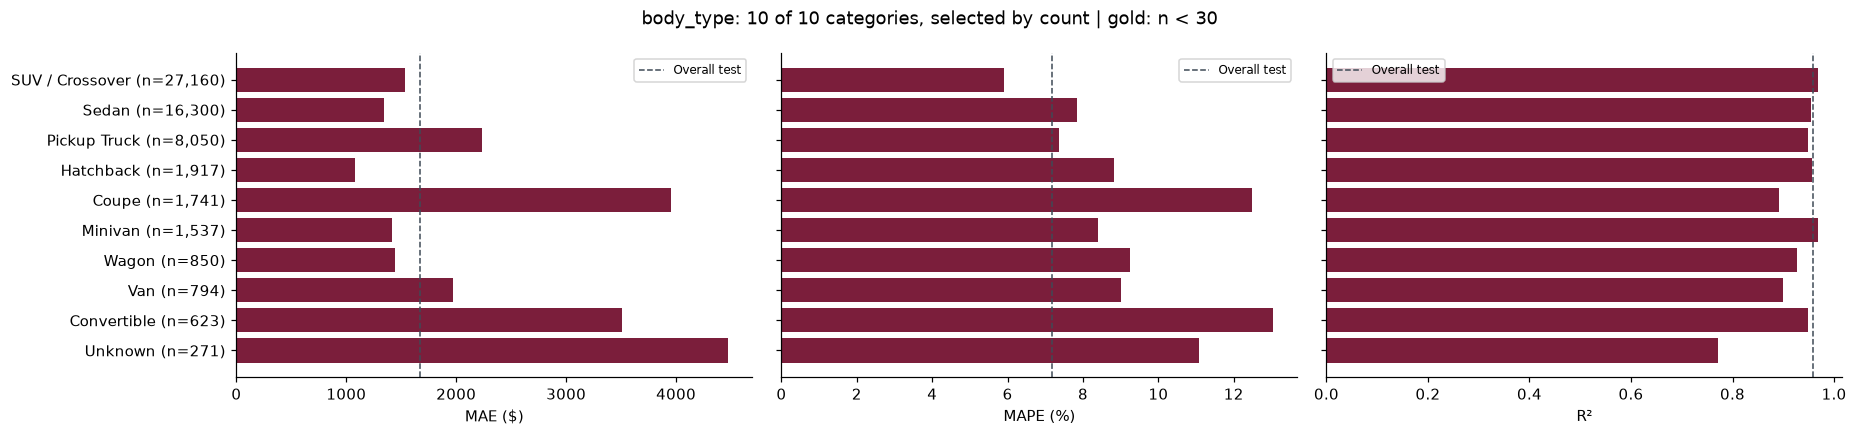

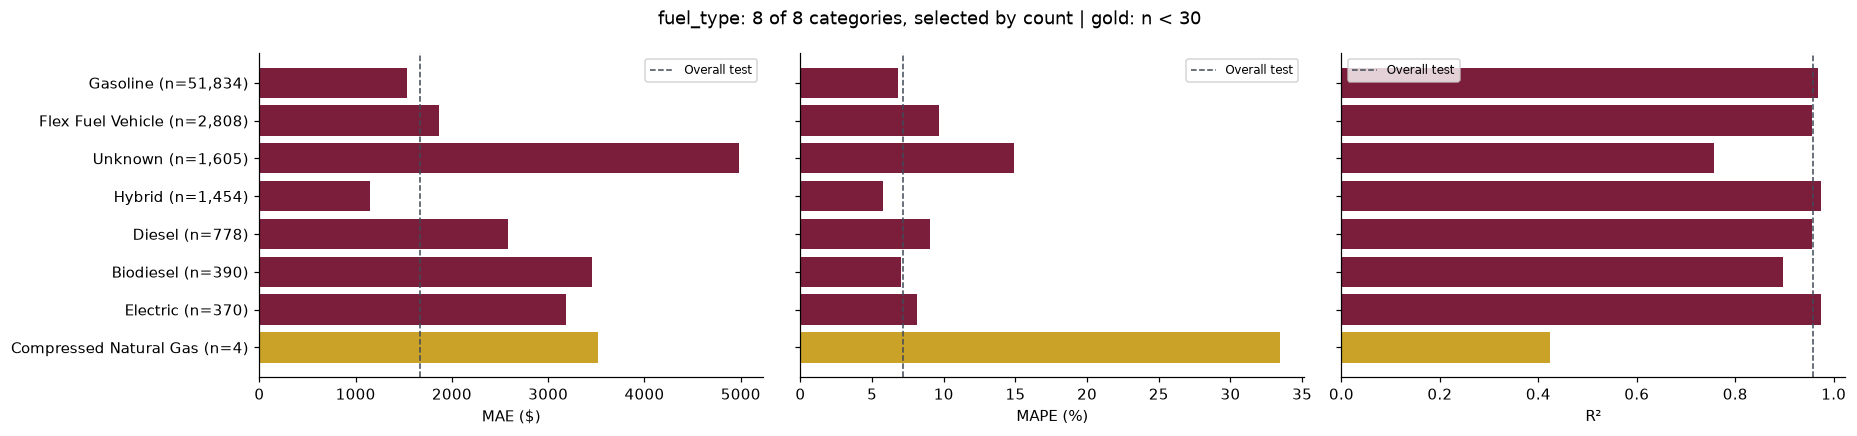

In [10]:
for column, table in audit_tables.items():
    plot_data = table.sort_values("n", ascending=False).head(15).iloc[::-1]
    labels = [f"{name} (n={int(row['n']):,})" for name, row in plot_data.iterrows()]
    colors = [GOLD if small else MAROON for small in plot_data["small_group"]]
    fig, axes = plt.subplots(1, 3, figsize=(17, max(4, len(plot_data) * 0.34)), sharey=True)
    for ax, key, title, reference in zip(axes, ["MAE", "MAPE_percent", "R2"],
                                        ["MAE ($)", "MAPE (%)", "R²"],
                                        [overall["MAE"], overall["MAPE"] * 100, overall["R2"]]):
        ax.barh(labels, plot_data[key], color=colors)
        ax.axvline(reference, color=SLATE, linestyle="--", linewidth=1, label="Overall test")
        ax.set_xlabel(title)
        ax.legend(fontsize=8)
    fig.suptitle(f"{column}: {len(plot_data)} of {len(table)} categories, selected by count | gold: n < {MIN_GROUP_N}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"audit_{column}.png", bbox_inches="tight", dpi=160)
    plt.show()


### 5.2 Quantify gaps and interpret the observed evidence
A max-minus-min gap summarizes dispersion without declaring one category a normative reference. We report Fairlearn's gap over all groups, plus a separate gap among groups with at least 30 observations. The largest and smallest errors may belong to different groups for different metrics. R² depends on a group's price variance, so its gap is descriptive and is not interchangeable with an MAE gap.


In [11]:
disparity_rows = []
for column, table in audit_tables.items():
    all_gaps = audit_frames[column].difference(method="between_groups")
    eligible = table.loc[table["n"] >= MIN_GROUP_N]
    for metric in ["MAE", "MAPE", "R2"]:
        valid = eligible[metric].dropna()
        disparity_rows.append({"dimension": column, "metric": metric,
                               "all_group_gap": all_gaps[metric],
                               "n_at_least_30_gap": valid.max() - valid.min() if len(valid) >= 2 else np.nan})
    if len(eligible) >= 2:
        high, low = eligible["MAE"].idxmax(), eligible["MAE"].idxmin()
        high_row, low_row = eligible.loc[high], eligible.loc[low]
        display(Markdown(f"**{column}:** among groups with at least {MIN_GROUP_N} test listings, "
                         f"`{high}` has the largest MAE (\\${high_row.MAE:,.0f}; n={int(high_row.n):,}), "
                         f"and `{low}` has the smallest (\\${low_row.MAE:,.0f}; n={int(low_row.n):,}). "
                         f"Their mean actual prices are \\${high_row.mean_price:,.0f} and \\${low_row.mean_price:,.0f}; "
                         f"their MAPEs are {high_row.MAPE:.2%} and {low_row.MAPE:.2%}. "
                         f"For `{high}`, mean signed error is \\${high_row.mean_signed_error:+,.0f}. "
                         "Compare dollar and proportional errors before attributing the gap to the model."))
    else:
        display(Markdown(f"**{column}:** fewer than two groups meet the count threshold; "
                         "no stable-group gap is reported."))
disparities = pd.DataFrame(disparity_rows)
display(disparities.round(4))


**make_name:** among groups with at least 30 test listings, `Porsche` has the largest MAE (\$8,612; n=380), and `Honda` has the smallest (\$824; n=4,217). Their mean actual prices are \$79,636 and \$24,180; their MAPEs are 10.82% and 4.65%. For `Porsche`, mean signed error is \$-4,153. Compare dollar and proportional errors before attributing the gap to the model.

**body_type:** among groups with at least 30 test listings, `Unknown` has the largest MAE (\$4,471; n=271), and `Hatchback` has the smallest (\$1,081; n=1,917). Their mean actual prices are \$39,704 and \$16,550; their MAPEs are 11.08% and 8.82%. For `Unknown`, mean signed error is \$-719. Compare dollar and proportional errors before attributing the gap to the model.

**fuel_type:** among groups with at least 30 test listings, `Unknown` has the largest MAE (\$4,985; n=1,605), and `Hybrid` has the smallest (\$1,150; n=1,454). Their mean actual prices are \$38,458 and \$25,636; their MAPEs are 14.87% and 5.73%. For `Unknown`, mean signed error is \$-316. Compare dollar and proportional errors before attributing the gap to the model.

,dimension,metric,all_group_gap,n_at_least_30_gap
0,make_name,MAE,40208.7015,7787.6652
1,make_name,MAPE,1.1513,0.4622
2,make_name,R2,8.8314,0.9264
3,body_type,MAE,3389.7491,3389.7491
4,body_type,MAPE,0.0712,0.0712
5,body_type,R2,0.1976,0.1976
6,fuel_type,MAE,3834.9993,3834.9993
7,fuel_type,MAPE,0.2775,0.0914
8,fuel_type,R2,0.5513,0.2188


### Observed results from the rebuilt model

The rebuilt forest achieved **MAE \$1,666.53**, **MAPE 7.18%**, and **R² 0.9577** on 59,243 held-out listings. This is a new run on the supplied Notebook 2 preprocessing, including its \$1,000–\$200,000 price restriction; it is not directly comparable to the original Notebook 4 population.

The largest mean absolute SHAP contributions in the 200-listing sample came from **torque_lbft**, **mileage**, **fuel_tank_volume**, **year**, **vehicle_age**. These are associations used by the saved model. They do not establish that changing these attributes would cause the corresponding price changes.

**make_name:** among groups with at least 30 observations, Porsche had the highest MAE (\$8,612; n=380), compared with \$824 for Honda. The largest MAPE was 50.87% for Pontiac. Mean actual price for Porsche was \$79,636, and its signed error averaged \$-4,153. These contrasts identify groups to investigate, while price scale and group support must be considered before assigning a cause.

**body_type:** among groups with at least 30 observations, Unknown had the highest MAE (\$4,471; n=271), compared with \$1,081 for Hatchback. The largest MAPE was 13.04% for Convertible. Mean actual price for Unknown was \$39,704, and its signed error averaged \$-719. These contrasts identify groups to investigate, while price scale and group support must be considered before assigning a cause.

**fuel_type:** among groups with at least 30 observations, Unknown had the highest MAE (\$4,985; n=1,605), compared with \$1,150 for Hybrid. The largest MAPE was 14.87% for Unknown. Mean actual price for Unknown was \$38,458, and its signed error averaged \$-316. These contrasts identify groups to investigate, while price scale and group support must be considered before assigning a cause.

Across these audits, dollar error, proportional error, and R² answer different questions. Use the explanations below to distinguish potential data coverage, model limitations, and vehicle-price composition. The observed disparities alone cannot identify which explanation is causal.

**Interpretation and follow-up priorities:** Higher torque and lower mileage generally push predictions upward in the beeswarm, which is plausible for vehicle value. Porsche's high dollar error partly accompanies its higher mean price, although its 10.82% MAPE also exceeds the overall 7.18%. Pontiac's 50.87% MAPE, based on only 49 test listings with mean price about \$8,108, deserves separate inspection; clearing the 30-row flag does not make that estimate precise. Unknown body and fuel categories suggest a data-completeness issue to investigate. These are evidence-based priorities, not established causal diagnoses.

## 6. Discussion: data, model, or price structure?
**Data explanation.** Sparse or noisy categories can produce unstable estimates. The count flags identify small *test* groups but do not prove training underrepresentation; inspect the matching training metadata before making that claim. Missing condition/history information and the prior top-20 categorical encoding can hide meaningful differences. Pooling rare levels into omitted dummy patterns may make categories harder to distinguish.

**Model explanation.** Higher MAPE together with a consistent signed error would motivate checking systematic under- or overprediction within that group. Compare similar-price and similar-age vehicles before concluding that group membership drives error. VIF filtering and tree importance can remove information useful to a small subgroup, even when aggregate accuracy remains high. A follow-up could compare full-feature and selected-feature models on the same held-out rows; this notebook does not assume selection caused any observed gap.

**Feature–target explanation.** Higher MAE accompanied by similar MAPE and higher mean prices can partly reflect the larger dollar scale of expensive vehicles. A narrow within-group price range can depress R². These patterns help form hypotheses but do not prove that disparity is inevitable or acceptable. `MAE_over_mean_price` is a supplementary normalized summary, not MAPE.

**Limits inherited from the pipeline.** The provided Notebook 2 fits its scaler before splitting and also learns preprocessing decisions on the combined data. That exposes held-out feature-distribution information and should be corrected in a future complete training run. Notebook 4 selects features once before cross-validation, so those CV scores do not fully capture selection uncertainty. The original project test split was used to compare models. This rebuild also inherits parameter choices from that prior work and is not a new independent deployment validation. The pseudoinverse used for VIF in Notebook 4 can mask exact dependencies if the correlation matrix is singular. These issues do not prevent describing the saved forest, but they limit claims about generalization.

**Practical conclusion.** Read the generated global ranking, four case explanations, and three subgroup comparisons together. The audit establishes where observed errors differ; it does not isolate their cause. Investigate the largest well-supported proportional-error gaps, inspect data quality and training coverage, and evaluate any remedy on new held-out data. Do not declare the model “fair” solely because overall R² is high or because these three audits show small gaps.


## 7. Export evidence and record the run
Save the figures, complete subgroup tables, per-row predictions, selected cases, SHAP contributions, and input hashes so the audit is traceable to an exact model/data pair. These files are written only after the preceding analysis succeeds. Save the executed notebook with outputs for the assignment; do not replace the team's actual environment export with a guessed dependency list.


In [12]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

overall.to_frame().T.to_csv(OUTPUT_DIR / "overall_metrics.csv", index=False)
evaluation.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
case_table.to_csv(OUTPUT_DIR / "local_cases.csv", index=False)
shap_importance.to_csv(OUTPUT_DIR / "shap_importance.csv", index=False)
pd.concat(local_contributions, ignore_index=True).to_csv(OUTPUT_DIR / "local_shap_contributions.csv", index=False)
disparities.to_csv(OUTPUT_DIR / "subgroup_disparities.csv", index=False)
for column, table in audit_tables.items():
    table.to_csv(OUTPUT_DIR / f"audit_{column}.csv", index_label=column)
np.savez_compressed(OUTPUT_DIR / "global_shap_values.npz", values=shap_values.values,
                    base_values=shap_values.base_values, test_rows=X_shap.index.to_numpy(),
                    feature_names=np.asarray(feature_names, dtype=str))
manifest = {"model": str(MODEL_PATH.resolve()), "model_sha256": sha256_file(MODEL_PATH),
            "test_data": str(TEST_PATH.resolve()), "test_sha256": sha256_file(TEST_PATH),
            "shap_method": "tree_path_dependent, averaged over all 200 trees",
            "shap_workers": SHAP_WORKERS,
            "test_rows": len(test_df), "features": feature_names, "seed": SEED,
            "shap_sample_size": len(X_shap), "audit_columns": AUDIT_COLUMNS,
            "python": platform.python_version(),
            "packages": {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "shap", "fairlearn", "matplotlib", "joblib"]}}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
assert all((OUTPUT_DIR / f"force_{i}.png").exists() for i in range(1, 5))
assert all((OUTPUT_DIR / f"audit_{c}.csv").exists() for c in AUDIT_COLUMNS)
print("Analysis complete. Reports saved to:", OUTPUT_DIR.resolve())
print("Save this notebook with outputs intact after reviewing the figures and interpretation.")


Analysis complete. Reports saved to: /Users/ironcloth/Documents/Codex/2026-09-22/hel/outputs/Notebook5_Project/reports/notebook5
Save this notebook with outputs intact after reviewing the figures and interpretation.


## References and requirement coverage
- **P1_Prompt.pdf, page 7:** selected test/model input (Section 1); small random SHAP sample and beeswarm (Section 3); two close and two large-error force plots (Section 4); at least three metadata audits using MetricFrame with MAE/MAPE/R², plots, and discussion (Sections 5–6).
- **Team DataStars Notebooks 1–4:** preprocessing history, metadata convention, model choice, exported filenames, and recorded baseline metrics. Prior figures quoted here come from saved code outputs, not newly executed results.
- [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), [beeswarm interpretation](https://shap.readthedocs.io/en/stable/example_notebooks/api_examples/plots/beeswarm.html), and [force plot API](https://shap.readthedocs.io/en/latest/generated/shap.plots.force.html).
- [Fairlearn MetricFrame](https://fairlearn.org/main/api_reference/generated/fairlearn.metrics.MetricFrame.html).
